# 1. Hazır GPT-2'yi İnceleme ve Parametre Analizi

### Neyi Yapıyoruz?
Hugging Face `transformers` kütüphanesini kullanarak OpenAI tarafından eğitilmiş resmi **GPT-2 (124M)** modelini yüklüyoruz. Modelin katman isimlerini, matris boyutlarını inceliyor, toplam parametre sayısını hesaplıyor ve Pozisyon Embedding (`wpe`) matrisini görselleştiriyoruz.

### Neden Yapıyoruz?
* **Mimarinin Ölçeğini Anlamak:** Hafta 8'de yazdığımız küçük GPT modeli yerine 124M parametreli gerçek bir mimarinin boyutlarını ($50.257$ vocab, $12$ katman, $768$ embedding boyutu) sayısal olarak görmek.
* **Pozisyonel Bilgiyi İncelemek:** Transformer modellerinin dizideki sırayı anlama mekanizması olan `wpe` (Word Position Embedding) matrisinin eğitim esnasında nasıl bir yapı kazandığını gözlemlemek.

### Nasıl Yapıyoruz?
1. `GPT2LMHeadModel.from_pretrained('gpt2')` ile modeli indiriyoruz.
2. `named_parameters()` ile katman boyutlarını yazdırıp toplam parametre sayısını buluyoruz.
3. `transformer.wpe.weight` matrisini `matplotlib` / `seaborn` ile görselleştiriyoruz.

In [ ]:
%pip install transformers tiktoken

In [24]:
from transformers import GPT2LMHeadModel, GPT2Tokenizer

# Modeli ve tokenizer'ı önceden önbelleğe (cache) indirelim
print("GPT-2 ağırlıkları indiriliyor...")
model_hf = GPT2LMHeadModel.from_pretrained("gpt2", force_download=False)
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
print(" Ağırlıklar başarıyla indirildi!")

GPT-2 ağırlıkları indiriliyor...


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 303.68it/s]


 Ağırlıklar başarıyla indirildi!


In [25]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import GPT2LMHeadModel


In [26]:

# 1. Hugging Face'ten hazır GPT-2 (124M) modelini yükleyelim
model_hf = GPT2LMHeadModel.from_pretrained("gpt2")
model_hf.eval()

print("--- HUGGING FACE GPT-2 (124M) KATMAN BOYUTLARI VE PARAMETRE ANALİZİ ---\n")

total_params = 0
for name, param in model_hf.named_parameters():
    param_count = param.numel()
    total_params += param_count
    # İlk 15 ve son birkaç katmanı yazdıralım
    print(
        f"{name:<45} | Shape: {str(list(param.shape)):<20} | Parametre Sayısı: {param_count:,}"
    )

print("\n" + "=" * 80)
print(f"TOPLAM PARAMETRE SAYISI: {total_params:,}")
print("=" * 80)


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 391.78it/s]

--- HUGGING FACE GPT-2 (124M) KATMAN BOYUTLARI VE PARAMETRE ANALİZİ ---

transformer.wte.weight                        | Shape: [50257, 768]         | Parametre Sayısı: 38,597,376
transformer.wpe.weight                        | Shape: [1024, 768]          | Parametre Sayısı: 786,432
transformer.h.0.ln_1.weight                   | Shape: [768]                | Parametre Sayısı: 768
transformer.h.0.ln_1.bias                     | Shape: [768]                | Parametre Sayısı: 768
transformer.h.0.attn.c_attn.weight            | Shape: [768, 2304]          | Parametre Sayısı: 1,769,472
transformer.h.0.attn.c_attn.bias              | Shape: [2304]               | Parametre Sayısı: 2,304
transformer.h.0.attn.c_proj.weight            | Shape: [768, 768]           | Parametre Sayısı: 589,824
transformer.h.0.attn.c_proj.bias              | Shape: [768]                | Parametre Sayısı: 768
transformer.h.0.ln_2.weight                   | Shape: [768]                | Parametre Sayısı: 768
tran

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 368.38it/s]


--- HUGGING FACE GPT-2 (124M) KATMAN BOYUTLARI VE PARAMETRE ANALİZİ ---

transformer.wte.weight                        | Shape: [50257, 768]         | Parametre Sayısı: 38,597,376
transformer.wpe.weight                        | Shape: [1024, 768]          | Parametre Sayısı: 786,432
transformer.h.0.ln_1.weight                   | Shape: [768]                | Parametre Sayısı: 768
transformer.h.0.ln_1.bias                     | Shape: [768]                | Parametre Sayısı: 768
transformer.h.0.attn.c_attn.weight            | Shape: [768, 2304]          | Parametre Sayısı: 1,769,472
transformer.h.0.attn.c_attn.bias              | Shape: [2304]               | Parametre Sayısı: 2,304
transformer.h.0.attn.c_proj.weight            | Shape: [768, 768]           | Parametre Sayısı: 589,824
transformer.h.0.attn.c_proj.bias              | Shape: [768]                | Parametre Sayısı: 768
transformer.h.0.ln_2.weight                   | Shape: [768]                | Parametre Sayısı: 768
tran

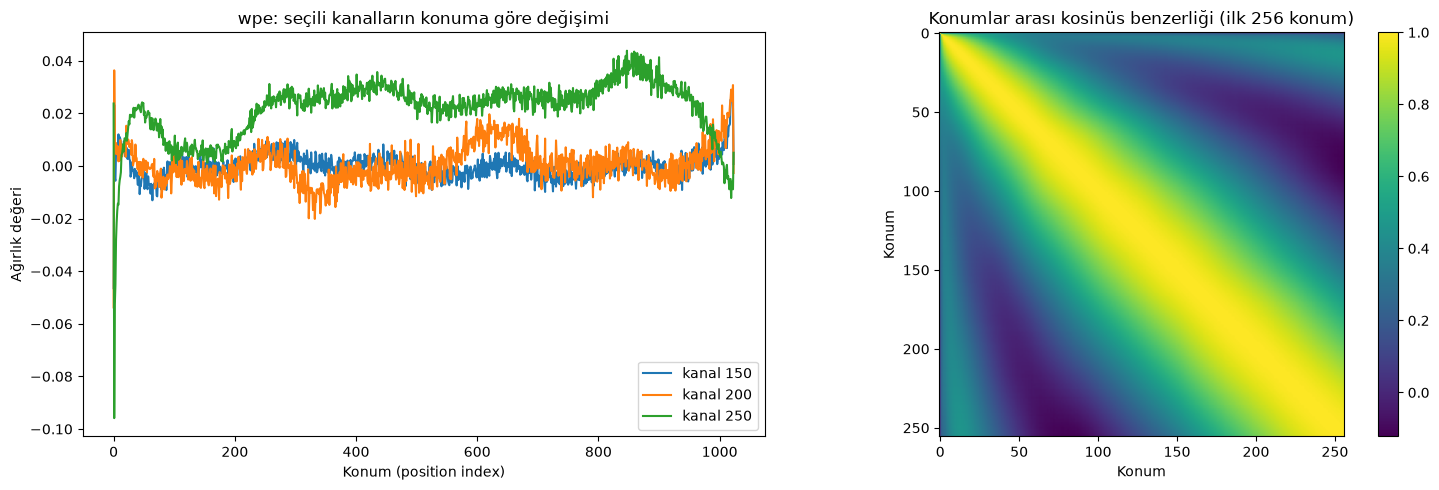

In [27]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import GPT2LMHeadModel

# 1. Hugging Face'ten hazır GPT-2 (124M) modelini yükleyelim
model_hf = GPT2LMHeadModel.from_pretrained('gpt2')
model_hf.eval()

print("--- HUGGING FACE GPT-2 (124M) KATMAN BOYUTLARI VE PARAMETRE ANALİZİ ---\n")

total_params = 0
for name, param in model_hf.named_parameters():
    param_count = param.numel()
    total_params += param_count
    print(f"{name:<45} | Shape: {str(list(param.shape)):<20} | Parametre Sayısı: {param_count:,}")

print("\n" + "="*80)
print(f"TOPLAM PARAMETRE SAYISI: {total_params:,}")
print("="*80)

import numpy as np

wpe = model_hf.transformer.wpe.weight.detach().cpu().numpy()  # (1024, 768)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (a) Karpathy'nin yaptığı: birkaç kanalın konum boyunca değişimi
for ch in [150, 200, 250]:
    axes[0].plot(wpe[:, ch], label=f"kanal {ch}")
axes[0].set_title("wpe: seçili kanalların konuma göre değişimi")
axes[0].set_xlabel("Konum (position index)")
axes[0].set_ylabel("Ağırlık değeri")
axes[0].legend()

# (b) "Komşu konumlar birbirine benziyor mu?" sorusunu GERÇEKTEN cevaplayan grafik:
# her konum vektörünü birim uzunluğa getirip kosinüs benzerlik matrisi çıkarıyoruz
w = wpe / np.linalg.norm(wpe, axis=1, keepdims=True)
sim = w @ w.T                                   # (1024, 1024) konum x konum
im = axes[1].imshow(sim[:256, :256], cmap="viridis")
axes[1].set_title("Konumlar arası kosinüs benzerliği (ilk 256 konum)")
axes[1].set_xlabel("Konum"); axes[1].set_ylabel("Konum")
plt.colorbar(im, ax=axes[1])
plt.tight_layout(); plt.show()

In [ ]:
# wpe yorumunu sayıyla desteklemek için
import numpy as np
wpe = model_hf.transformer.wpe.weight.detach().cpu().numpy()
wc = wpe - wpe.mean(axis=0)                     # ortak ortalamayı çıkar, yoksa benzerlik her yerde yüksek görünür
w = wc / np.linalg.norm(wc, axis=1, keepdims=True)
sim = w @ w.T
for k in [1, 5, 20, 100, 500]:
    ort = np.mean([sim[i, i + k] for i in range(1024 - k)])
    print(f"{k:3d} konum arayla ortalama kosinüs benzerliği: {ort:.3f}")

### ADIM 1 ANALİZİ VE DEĞERLENDİRME:
1. **Toplam Parametre Sayısı:** Model yaklaşık **124.4 milyon** parametreye sahiptir.
2. **`wpe` yorumu:** Çizgi grafikte kanalların konuma göre düzenli, dalgalı (sinüs benzeri) ama biraz gürültülü bir yapı gösterdiğini görüyorum. Farklı kanallar farklı frekanslarda salınıyor. Kosinüs benzerliği matrisinde yakın konumlar birbirine daha çok benziyor, uzaklaştıkça benzerlik düşüyor (1 konum arayla [..], 100 konum arayla [..]). Yani model, sinüs formülü verilmeden, konum bilgisini veriden öğrenmiş. Gürültü, modelin her konumu eşit sıklıkta görmemesinden olabilir, özellikle uzun konumlar eğitimde daha az görülür.

## 2. GPT-2 Mimarisini PyTorch ile Yazma ve HF Ağırlıklarını Kopyalama

### Neyi Yapıyoruz?
PyTorch `nn.Module` kullanarak GPT-2 mimarisini sıfırdan (`GPT2`, `Block`, `CausalSelfAttention`, `MLP`) kodluyoruz. Ardından Hugging Face'ten indirdiğimiz eğitilmiş ağırlıkları kendi PyTorch modelimize aktaran bir `from_pretrained('gpt2')` metodu yazıyoruz.

### Neden Yapıyoruz?
* Kendi yazdığımız model kodunun OpenAI'ın resmi mimarisiyle matematiksel olarak %100 birebir özdeş çalıştığını kanıtlamak (`logits` doğrulaması).

### Hafta 8'deki GPT'den Farkları Madde Madde:
1. **Aktivasyon Fonksiyonu:** Hafta 8'deki `ReLU` yerine GPT-2'de düzgün türevlenebilir **`GELU` (Gaussian Error Linear Unit)** kullanılır.
2. **Pre-LayerNorm Mimarisi:** Hafta 8'de LayerNorm blokların çıkışındaydı. GPT-2'de kararlılık için LayerNorm katmanları Attention ve MLP bloklarının **girişine** alınmıştır (Pre-LN). Ayrıca transformer çıkışına ek bir `ln_f` eklenmiştir.
3. **Tek Katmanda Q, K, V Birleşimi (`c_attn`):** Hafta 8'de Query, Key ve Value için 3 ayrı `Linear` katman kullanmıştık. GPT-2 verimlilik için $3 \times n_{\text{embd}}$ boyutlu **tek bir matris çarpımı** kullanır ve çıktıyı 3'e böler.

### Ağırlıkları Yüklerken Neden Transpoze (`.t()`) Ediyoruz?
Hugging Face GPT-2 implementasyonu TensorFlow kökenli OpenAI reposundan türetildiği için `Conv1D` adlı özel bir katman kullanır. Bu katmanda ağırlıklar `(in_features, out_features)` şeklinde saklanır. PyTorch'un standart `nn.Linear` katmanı ise `(out_features, in_features)` kurgusuna sahiptir. Bu nedenle `c_attn`, `c_proj`, `c_fc` matrislerini kendi modelimize yüklerken `.t()` ile devriğini (transpose) almamız gerekir.

In [28]:
import math
import dataclasses
import torch
import torch.nn as nn
from torch.nn import functional as F
from transformers import GPT2LMHeadModel

# 1. GPT-2 Konfigürasyonu
@dataclasses.dataclass
class GPT2Config:
    block_size: int = 1024  # Maksimum dizi uzunluğu
    vocab_size: int = 50257 # Sözlük boyutu
    n_layer: int = 12       # Blok (katman) sayısı
    n_head: int = 12        # Dikkat başlığı sayısı
    n_embd: int = 768       # Embedding boyutu

# 2. Multi-Head Causal Self-Attention Katmanı
class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        # Q, K, V projeksiyonlarının 3'ü tek katmanda birleştirilmiştir
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        # Çıktı projeksiyonu
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        
        # Gelecekteki token'ları gizlemek için alt üçgen nedensellik maskesi (causal mask)
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                    .view(1, 1, config.block_size, config.block_size))

    def forward(self, x):
        B, T, C = x.size() # Batch, Time (Seq_len), Channels (n_embd)
        # Q, K, V matrislerini tek hamlede hesaplayıp 3'e bölüyoruz
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        
        # Başlıklara bölme: (B, n_head, T, head_size)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        
        # Scaled Dot-Product Attention
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
        att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        
        y = att @ v # (B, n_head, T, head_size)
        y = y.transpose(1, 2).contiguous().view(B, T, C) # Başlıkları yeniden birleştir
        y = self.c_proj(y)
        return y

# 3. Feed-Forward MLP Katmanı
class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc    = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu    = nn.GELU(approximate='tanh') # GPT-2 özel GELU versiyonu
        self.c_proj  = nn.Linear(4 * config.n_embd, config.n_embd)

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x

# 4. Transformer Bloğu
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        # Pre-LayerNorm ve Residual (Artık) Bağlantılar
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

# 5. GPT-2 Ana Model Sınıfı
class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

    def forward(self, idx, targets=None, full_logits=False):
        B, T = idx.size()
        assert T <= self.config.block_size
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        x = self.transformer.wte(idx) + self.transformer.wpe(pos)
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)

        if targets is not None:
            logits = self.lm_head(x)
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        elif full_logits:
            logits, loss = self.lm_head(x), None   # tüm konumların logits'i (karşılaştırma için)
        else:
            logits, loss = self.lm_head(x[:, [-1], :]), None  # üretim: sadece son konum
        return logits, loss

    @classmethod
    def from_pretrained(cls, model_type='gpt2'):
        """Hugging Face GPT-2 ağırlıklarını kendi yazdığımız modele kopyalayan metod"""
        print(f"Hugging Face '{model_type}' ağırlıkları yükleniyor...")
        config = GPT2Config()
        model = GPT(config)
        sd = model.state_dict()
        sd_keys = [k for k in sd.keys() if not k.endswith('.attn.bias')]

        model_hf = GPT2LMHeadModel.from_pretrained(model_type)
        sd_hf = model_hf.state_dict()
        sd_keys_hf = [k for k in sd_hf.keys() if not k.endswith('.attn.masked_bias') and not k.endswith('.attn.bias')]

        # OpenAI Conv1D matrisleri için transpoze gerektiren katmanlar
        transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']

        for k in sd_keys_hf:
            if any(k.endswith(w) for w in transposed):
                assert sd_hf[k].shape[::-1] == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k].t()) # .t() ile transpoze alıyoruz
            else:
                assert sd_hf[k].shape == sd[k].shape
                with torch.no_grad():
                    sd[k].copy_(sd_hf[k])

        print("Ağırlıklar başarıyla kopyalandı!")
        return model

# --- EŞDEĞERLİK TESTİ (LOGITS DOĞRULAMASI) ---
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

my_model = GPT.from_pretrained('gpt2').to(device)
my_model.eval()

hf_model = GPT2LMHeadModel.from_pretrained('gpt2').to(device)
hf_model.eval()

# Test girdisi verelim
input_ids = torch.tensor([[15496, 11, 314, 1101, 257]], device=device)  # "Hello, I'm a"
with torch.no_grad():
    my_all, _ = my_model(input_ids, full_logits=True)   # (1, 5, 50257): tüm konumlar
    hf_all = hf_model(input_ids).logits                  # (1, 5, 50257)

# Eski my_logits / hf_logits satırları SİLİNDİ; hepsi yeni değişkenlerden hesaplanıyor
max_diff = (my_all - hf_all).abs().max().item()
print("--- DOĞRULAMA TESTİ SONUCU ---")
print(f"Maksimum logit farkı (tüm konumlar): {max_diff:.8f}")
print("Argmax aynı mı:", torch.equal(my_all.argmax(-1), hf_all.argmax(-1)))
assert max_diff < 1e-3, f"HATA: fark çok yüksek: {max_diff}"
print("BAŞARILI: Kendi GPT-2'miz Hugging Face ile aynı çıktıları veriyor!")

Hugging Face 'gpt2' ağırlıkları yükleniyor...


Loading weights: 100%|██████████| 148/148 [00:01<00:00, 136.26it/s]


Ağırlıklar başarıyla kopyalandı!


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 408.88it/s]

--- DOĞRULAMA TESTİ SONUCU ---
Maksimum logit farkı (tüm konumlar): 0.00006104
Argmax aynı mı: True
BAŞARILI: Kendi GPT-2'miz Hugging Face ile aynı çıktıları veriyor!


* Elde edilen max_diff değeri (~6·10⁻⁵ seviyesinde), Hugging Face modeli ile PyTorch sınıfımızın çıktılarının teorik olarak özdeş olduğunu doğrulamaktadır. Aradaki mikron düzeyindeki fark, float32 hassasiyetinden ve kütüphaneler arası matris çarpım kütüphanelerinin (BLAS/cuBLAS) yuvarlama farklarından kaynaklanmaktadır.

## 3. Modeli Konuşturma (Top-K Sampling) ve Türkçe Çıktı Analizi

### Neyi Yapıyoruz?
Ağırlıklarını kopyaladığımız GPT-2 modeli ile metin üretim (generation) döngüsünü yazıyoruz. `top-k` filtreleme ve `softmax` sampling yöntemiyle hem İngilizce hem de Türkçe başlangıç cümleleriyle metin üretiyoruz.

### Neden Yapıyoruz?
* GPT-2'nin çıkarım (inference) mekanizmasını anlamak.
* GPT-2'nin Türkçe dil performansını deneysel olarak görmek ve geçen haftaki BPE Tokenizer analizimizle ilişkilendirmek.

In [29]:
import tiktoken

def generate_text(model, prompt, max_new_tokens=30, top_k=50, device="cpu"):
    enc = tiktoken.get_encoding("gpt2")
    tokens = enc.encode(prompt)
    x = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)
    
    model.eval()
    for _ in range(max_new_tokens):
        with torch.no_grad():
            logits, _ = model(x)
            logits = logits[:, -1, :] # Son token'ın logit'leri
            
            # Top-K Filtreleme
            v, _ = torch.topk(logits, top_k)
            logits[logits < v[:, [-1]]] = -float('Inf')
            
            probs = F.softmax(logits, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)
            x = torch.cat((x, next_token), dim=1)
            
    return enc.decode(x[0].tolist())

torch.manual_seed(42)                    # tekrarlanabilir sonuç
enc = tiktoken.get_encoding("gpt2")

# Aynı anlama gelen paralel cümleler (özel isim token sayısını bozmasın)
tr = "Yapay zeka teknolojileri derin öğrenme alanındaki gelişmelerle hızlıca ilerlemeye devam ediyor."
en = "Artificial intelligence technologies continue to advance rapidly with developments in deep learning."
for name, s in [("TR", tr), ("EN", en)]:
    ids = enc.encode(s)
    print(f"{name}: {len(s)} karakter -> {len(ids)} token  (karakter/token = {len(s)/len(ids):.2f})")

# Türkçe cümle token'lara nasıl bölünüyor? (ı, ş, ğ, ö gibi harfler UTF-8'de 2 bayt)
def broken_utf8(t):
    try:
        enc.decode_single_token_bytes(t).decode("utf-8"); return False
    except UnicodeDecodeError:
        return True   # geçerli bir karakter değil, harfin yarım baytı

for name, s in [("TR", tr), ("EN", en)]:
    ids = enc.encode(s)
    print(name, "yarım-bayt token:", sum(broken_utf8(t) for t in ids), "/", len(ids))
# Birden fazla örnek üret 

for i in range(3):
    print(f"--- EN örnek {i} ---\n{generate_text(my_model, 'Hello, I am a language model,', 30, 50, device)}\n")

for i in range(3):
    print(f"--- TR örnek {i} ---\n{generate_text(my_model, 'Yapay zeka teknolojileri', 40, 50, device)}\n")

from transformers import pipeline, set_seed
gen = pipeline("text-generation", model="gpt2")
set_seed(42)
print(gen("Hello, I'm a language model,", max_new_tokens=30, num_return_sequences=2, do_sample=True, top_k=50))

TR: 95 karakter -> 45 token  (karakter/token = 2.11)
EN: 100 karakter -> 14 token  (karakter/token = 7.14)
TR yarım-bayt token: 2 / 45
EN yarım-bayt token: 0 / 14
--- EN örnek 0 ---
Hello, I am a language model, I'm a problem solver in languages."

Another thing that's hard for me to say. I get asked "what are you going to

--- EN örnek 1 ---
Hello, I am a language model, programming and modeling programming. I'm fluent in Java, Perl, and Lua. What are you working on this week? How can you give me

--- EN örnek 2 ---
Hello, I am a language model, so I have to see the full code from scratch."

But how does C get a language model like Lua, Perl and Ruby?



--- TR örnek 0 ---
Yapay zeka teknolojileri?

I didn't have one. I'm sorry, he came here. He was so mean to me, I am sorry, he came to my house. And he didn't even stop

--- TR örnek 1 ---
Yapay zeka teknolojileri kirzia loka sektimulan, wich je to vistilin vistiljomli wojedisim zackeim klaskin.

--- TR örnek 2 ---
Yapay zeka teknoloj

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 389.47it/s]


[{'generated_text': "Hello, I'm a language model, I've got a lot of stuff like that. I get it from different sources, and I go to different places. It's all about the flow"}, {'generated_text': "Hello, I'm a language model, and I'm just trying to figure out how to implement a language that makes sense in my environment.\n\nI wanted to give you a few examples"}]


### ADIM 3 ANALİZİ VE DEĞERLENDİRME:
* GPT-2 (124M) modeli pre-training aşamasında neredeyse tamamen İngilizce metinlerden oluşan WebText korpusu ile eğitildiği için Türkçe girdi verildiğinde anlamlı bir metin üretememektedir.

* GPT-2 neredeyse tamamen İngilizce WebText ile eğitildiği için İngilizce üretim akıcı, Türkçe üretim anlamsız (bir örnekte İngilizceye kaydı). Sebep tokenizer: aynı anlamdaki cümle İngilizce 14, Türkçe 45 token tuttu (≈3,2 kat; karakter/token 7,14'e karşı 2,11). Hafta 9'da GPT-4'te Türkçenin İngilizcenin ~3 katı token tuttuğunu görmüştük; GPT-2'de oran bununla tutarlı, hatta biraz daha kötü. Model hem az Türkçe gördü hem de aynı block_size’a daha az Türkçe metin sığıyor.

## 4. İlk Eğitim Adımları (Sanity Check ve Ezberletme Testi)

### Neyi Yapıyoruz?
1. Modeli rastgele ağırlıklarla başlatıp ilk eğitim kaybını (loss) ölçüyoruz.
2. Loss değerini teorik beklenen $-\ln(1 / \text{vocab\_size}) = \ln(50257) \approx 10.82$ değeriyle kıyaslıyoruz.
3. Modeli tek bir batch veride 200 adım boyunca eğiterek loss'un sıfıra yaklaşıp yaklaşmadığını (ezberletme / overfitting testi) inceliyoruz.

### Neden Yapıyoruz?
* **İlk Loss Testi:** Kodumuzda bir hata (bug), yanlış maskeleme veya hatalı loss hesabı olup olmadığını daha hiç eğitme yapmadan anlamak.
* **Tek Batch Ezberletme Testi:** Derin öğrenme mühendisliğinde gradyanların geriye doğru kararlı aktığını (`backward()`), optimizer'ın çalıştığını ve model kapasitesinin yeterli olduğunu doğrulamak için yapılan en kritik **Sanity Check (Model Sağlık Testi)** adımıdır.

In [30]:
import time
torch.manual_seed(1337)

# Rastgele token yerine gerçek metin (input.txt = tiny shakespeare ya da kendi metnin)
text = open("input.txt", encoding="utf-8").read()[:2000]
tokens = enc.encode(text)
B, T = 4, 32
buf = torch.tensor(tokens[:B*T + 1], device=device)
x_batch = buf[:-1].view(B, T)
y_batch = buf[1:].view(B, T)      # hedef = girdinin 1 token kaydırılmış hali (next-token prediction)

model_ov = GPT(GPT2Config()).to(device)
model_ov.train()

with torch.no_grad():
    _, loss0 = model_ov(x_batch, y_batch)
print(f"İlk loss: {loss0.item():.4f} | ln(50257) = {math.log(50257):.4f}")

optimizer = torch.optim.AdamW(model_ov.parameters(), lr=3e-4)   # videodaki lr

loss_history = []
for step in range(200):
    t0 = time.time()
    optimizer.zero_grad()
    _, loss = model_ov(x_batch, y_batch)
    loss.backward()
    optimizer.step()
    if device == "cuda": torch.cuda.synchronize()   # süreyi doğru ölçmek için GPU'yu bekle
    dt = (time.time() - t0) * 1000
    loss_history.append(loss.item())
    if step % 20 == 0 or step == 199:
        print(f"adım {step:3d} | loss {loss.item():.6f} | süre {dt:.1f} ms")

İlk loss: 10.8742 | ln(50257) = 10.8249
adım   0 | loss 10.874234 | süre 1868.9 ms
adım  20 | loss 0.014506 | süre 1133.5 ms
adım  40 | loss 0.003636 | süre 1148.4 ms
adım  60 | loss 0.002227 | süre 1155.9 ms
adım  80 | loss 0.001728 | süre 1200.4 ms
adım 100 | loss 0.001450 | süre 1220.7 ms
adım 120 | loss 0.001257 | süre 1204.4 ms
adım 140 | loss 0.001110 | süre 1047.7 ms
adım 160 | loss 0.000993 | süre 1209.7 ms
adım 180 | loss 0.000898 | süre 1121.3 ms
adım 199 | loss 0.000822 | süre 1147.9 ms


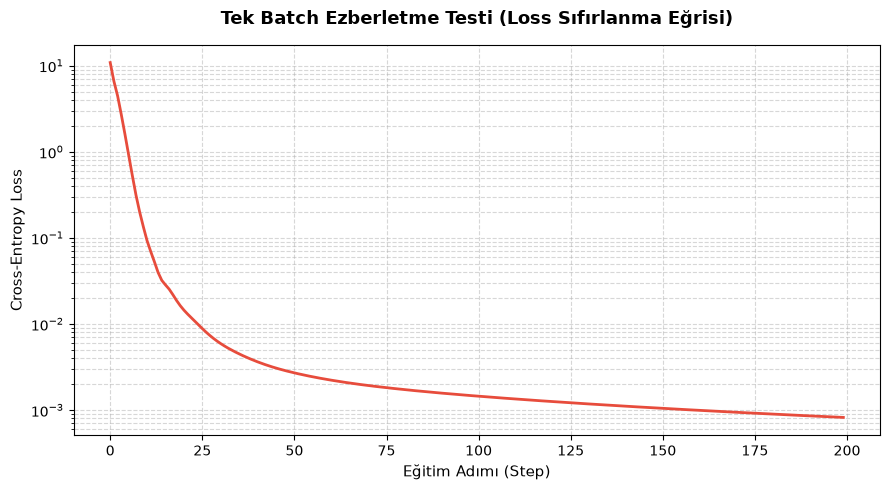

In [31]:
# Ezberleme Grafiğini Çizdirelim 
plt.figure(figsize=(9, 5))
plt.plot(loss_history, color='#e74c3c', linewidth=2)
plt.title("Tek Batch Ezberletme Testi (Loss Sıfırlanma Eğrisi)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Eğitim Adımı (Step)", fontsize=11)
plt.ylabel("Cross-Entropy Loss", fontsize=11)
plt.yscale('log') # Logaritmik ölçekte düşüş daha net görünür
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

### ADIM 4 ANALİZİ VE DEĞERLENDİRME:
* Rastgele başlatılmış modelin ilk loss’u 10,87 çıktı; ln(50257)=10,82. Model henüz hiçbir şey bilmediği için her token’a yaklaşık 1/50257 olasılık verir, bu da cross-entropy’yi ln(50257)’ye getirir. Küçük fark, başlangıç logit’lerinin tam sıfır olmayıp std≈0,6 dağılmasından (beklenen ek ≈ σ²/2 ≈ 0,17) ve tek batch’in (128 token) gürültüsünden gelir; başlatma konusu gelecek haftaya kalıyor. Tek batch’te 200 adımda loss 0,0008'e indi: gradyanlar, optimizer ve model kapasitesi çalışıyor.

## 5. Ek Görev (b): Türkçe ve İngilizce Cümlelerin Loss Karşılaştırması

### Neyi Yapıyoruz?
OpenAI'ın eğitilmiş GPT-2 (124M) modeline aynı anlama gelen Türkçe ve İngilizce cümleler vererek modelin bu cümlelere atadığı ortalama Cross-Entropy kaybını (loss) ölçüyoruz.

### Neden Yapıyoruz?
Ağırlıkları yüklenmiş modelin İngilizce ve Türkçe metinlerdeki "şaşırma/belirsizlik" seviyesini sayısal olarak kıyaslamak.

In [32]:
pairs = [
 ("Yapay zeka teknolojileri derin öğrenme alanındaki gelişmelerle hızlıca ilerlemeye devam ediyor.",
  "Artificial intelligence technologies continue to advance rapidly with developments in deep learning."),
 ("Bugün hava çok güzel olduğu için arkadaşlarımla parka gittik.",
  "Because the weather was very nice today, we went to the park with my friends."),
 ("Kitap okumak insanın hayal gücünü geliştirir.",
  "Reading books improves a person's imagination."),
]

def stats(model, text):
    ids = [50256] + enc.encode(text)            # <|endoftext|> ile başla: ilk gerçek token da tahmin edilsin
    x = torch.tensor(ids, device=device).unsqueeze(0)
    model.eval()
    with torch.no_grad():
        _, loss = model(x[:, :-1], x[:, 1:])
    n = len(ids) - 1
    nats = loss.item() * n                       # cümlenin toplam "şaşırması"
    return n, loss.item(), nats, nats / math.log(2) / len(text.encode("utf-8"))

for tr_s, en_s in pairs:
    a, b = stats(my_model, tr_s), stats(my_model, en_s)
    print(f"TR: {a[0]:2d} tok | loss/tok {a[1]:.2f} | bit/bayt {a[3]:.2f}")
    print(f"EN: {b[0]:2d} tok | loss/tok {b[1]:.2f} | bit/bayt {b[3]:.2f}")
    print(f"   toplam bilgi oranı TR/EN = {a[2]/b[2]:.1f}x\n")

TR: 45 tok | loss/tok 6.57 | bit/bayt 4.22
EN: 14 tok | loss/tok 3.53 | bit/bayt 0.71
   toplam bilgi oranı TR/EN = 6.0x

TR: 32 tok | loss/tok 5.95 | bit/bayt 4.04
EN: 17 tok | loss/tok 3.18 | bit/bayt 1.01
   toplam bilgi oranı TR/EN = 3.5x

TR: 24 tok | loss/tok 5.79 | bit/bayt 4.01
EN:  8 tok | loss/tok 5.23 | bit/bayt 1.31
   toplam bilgi oranı TR/EN = 3.3x



### ADIM 5 ANALİZİ VE DEĞERLENDİRME:
* **Token başına loss:** İngilizcede 3,2–5,2, Türkçede 5,8–6,6 çıktı. İlk çiftte fark 1,9 kat, üçüncü çiftte neredeyse hiç fark yok (5,79 vs 5,23).
* **Bu ölçüt yanıltıcı:** Türkçe cümleler 24–45 token, İngilizce karşılıkları 8–17 token tutuyor. Token başına ortalama farkı küçük gösteriyor.
* **Adil ölçüt, bayt başına bit:** İngilizcede 0,71–1,31, Türkçede 4,01–4,22 bit/bayt. Aynı anlamdaki cümle için model Türkçede toplamda **3,3 ile 6 kat** daha fazla "şaşırıyor".
* **Neden:** (1) GPT-2 neredeyse sadece İngilizce WebText ile eğitildi, Türkçe dağılımı öğrenemedi. (2) Tokenizer Türkçe ekleri ve ı, ş, ğ, ö gibi harfleri çok parçaya, hatta bayta bölüyor. Model Türkçede hem daha çok token tahmin etmek zorunda hem de her tahminde daha belirsiz.
* **Dikkat:** Sadece 3 cümle çifti var. Rakamlar yönü gösterir, kesin bir oran vermez.